1. import library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Pengaturan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

print("Library berhasil diimpor.")

Library berhasil diimpor.


2. Load Hasil Agregasi

2.1. upload file zip

In [4]:
from google.colab import files
uploaded = files.upload()

Saving hasil_agregasi_traffic_accidents.zip to hasil_agregasi_traffic_accidents.zip


2.2. ekstraksi file zip

In [8]:
import zipfile
import os

ZIP_PATH = "/content/hasil_agregasi_traffic_accidents.zip"
AGGREGATED_DIR = "/content/hasil_agregasi_csv"

# Membuat folder penyimpanan
os.makedirs(AGGREGATED_DIR, exist_ok=True)

# Mengekstrak file ZIP
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(AGGREGATED_DIR)

print("File agregasi berhasil diekstrak.")
print(os.listdir(AGGREGATED_DIR))

File agregasi berhasil diekstrak.
['hasil_agregasi_traffic_accidents.parquet', 'hasil_agregasi_traffic_accidents.csv']


2.3. membaca file csv

In [11]:
# Direktori file CSV hasil agregasi
CSV_DIR = os.path.join(
    AGGREGATED_DIR,
    "hasil_agregasi_traffic_accidents.csv"
)

# Membaca seluruh hasil agregasi
accidents_by_year = pd.read_csv(f"{CSV_DIR}/accidents_by_year.csv")
accidents_by_month = pd.read_csv(f"{CSV_DIR}/accidents_by_month.csv")
accidents_by_injury = pd.read_csv(f"{CSV_DIR}/accidents_by_injury.csv")
accidents_by_type = pd.read_csv(f"{CSV_DIR}/accidents_by_type.csv")
accidents_by_weather = pd.read_csv(f"{CSV_DIR}/accidents_by_weather.csv")
accidents_by_road_surface = pd.read_csv(f"{CSV_DIR}/accidents_by_road_surface.csv")
accidents_by_hour = pd.read_csv(f"{CSV_DIR}/accidents_by_hour.csv")
accidents_by_day = pd.read_csv(f"{CSV_DIR}/accidents_by_day.csv")
accidents_by_cause = pd.read_csv(f"{CSV_DIR}/accidents_by_cause.csv")

print("Seluruh hasil agregasi berhasil dimuat.")

Seluruh hasil agregasi berhasil dimuat.


2.4. pemeriksaan data

In [12]:
# Menggabungkan seluruh DataFrame hasil agregasi
aggregation_data = {
    "Kecelakaan Berdasarkan Tahun": accidents_by_year,
    "Kecelakaan Berdasarkan Bulan": accidents_by_month,
    "Tingkat Keparahan Cedera": accidents_by_injury,
    "Jenis Kecelakaan": accidents_by_type,
    "Kondisi Cuaca": accidents_by_weather,
    "Kondisi Permukaan Jalan": accidents_by_road_surface,
    "Jam Kejadian": accidents_by_hour,
    "Hari Kejadian": accidents_by_day,
    "Penyebab Utama": accidents_by_cause
}

# Memeriksa ukuran setiap DataFrame
for name, data in aggregation_data.items():
    print(f"{name}: {data.shape[0]} baris, {data.shape[1]} kolom")

print("\nSeluruh data agregasi berhasil diperiksa.")

Kecelakaan Berdasarkan Tahun: 12 baris, 2 kolom
Kecelakaan Berdasarkan Bulan: 12 baris, 2 kolom
Tingkat Keparahan Cedera: 5 baris, 2 kolom
Jenis Kecelakaan: 2 baris, 2 kolom
Kondisi Cuaca: 12 baris, 2 kolom
Kondisi Permukaan Jalan: 7 baris, 2 kolom
Jam Kejadian: 24 baris, 2 kolom
Hari Kejadian: 7 baris, 2 kolom
Penyebab Utama: 40 baris, 2 kolom

Seluruh data agregasi berhasil diperiksa.


3. Visualisasi Data

3.1. kecelakaan berdasarkan tahun

menggunakan Line Chart karena Karena data berdasarkan tahun memiliki urutan waktu, sehingga perubahan jumlah kecelakaan dari tahun ke tahun lebih mudah diamati.

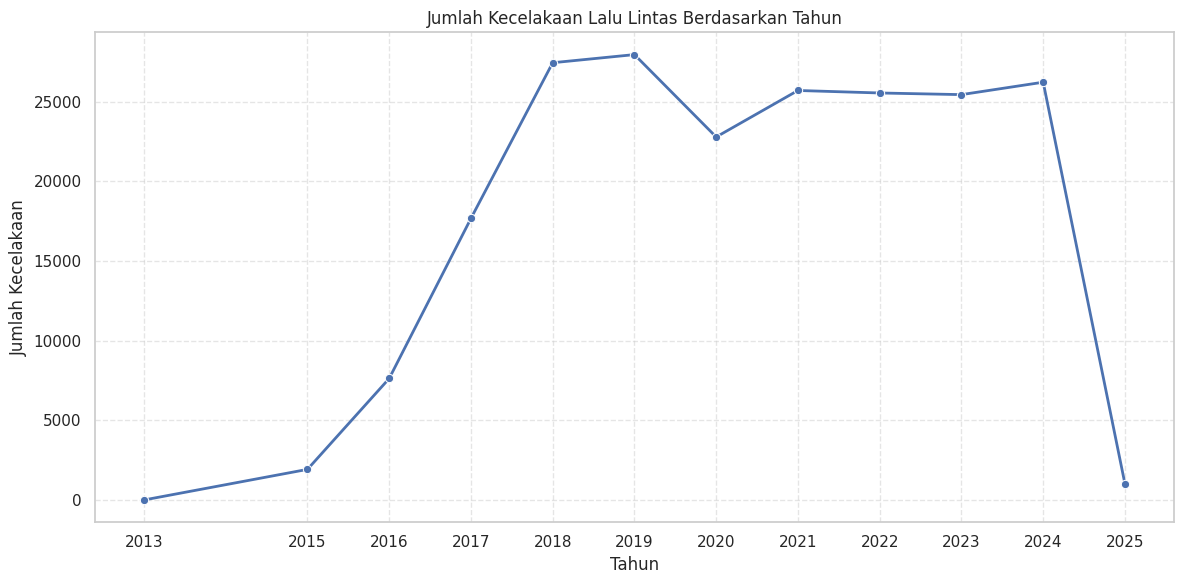

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
from google.colab import files

# Mengurutkan data berdasarkan tahun
year_data = accidents_by_year.sort_values("year")

# Membuat visualisasi
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=year_data,
    x="year",
    y="total_accidents",
    marker="o",
    linewidth=2
)

# Memberikan judul dan label
plt.title("Jumlah Kecelakaan Lalu Lintas Berdasarkan Tahun")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Kecelakaan")
plt.xticks(year_data["year"])
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

# Menyimpan grafik
plt.savefig(
    "accidents_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

# Menampilkan grafik
plt.show()

# Mengunduh grafik ke komputer
files.download("accidents_by_year.png")

3.2. kecelakaan berdasarkan bulan

menggunakan bar chart karena memudahkan perbandingan jumlah kecelakaan pada 12 bulan berdasarkan keseluruhan periode data.

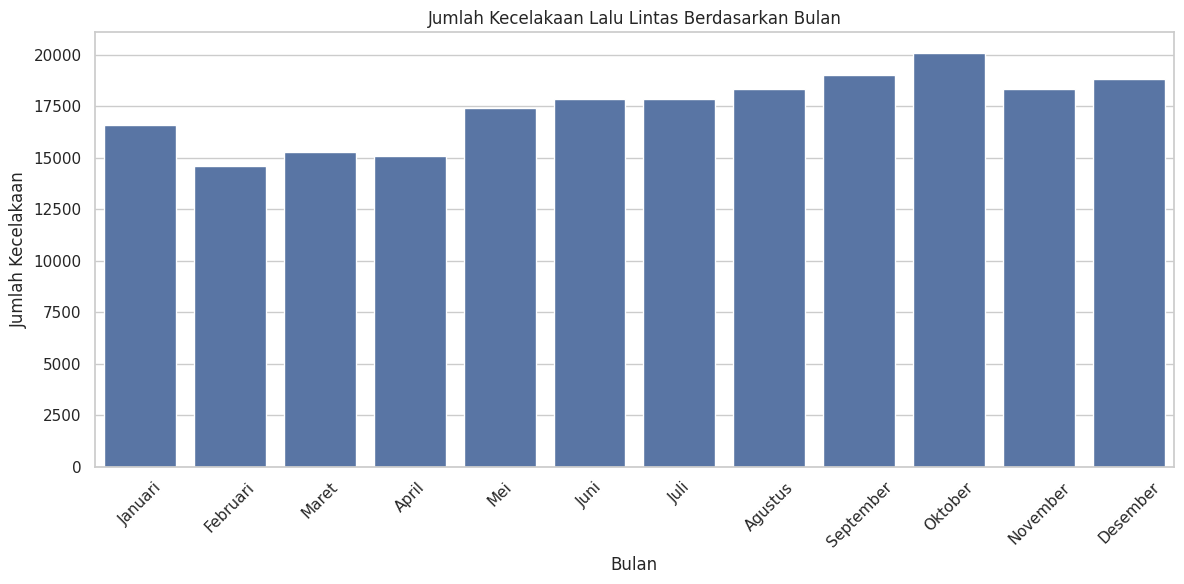

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# Mengurutkan data berdasarkan bulan
month_data = accidents_by_month.sort_values("crash_month")

# Membuat visualisasi
plt.figure(figsize=(12, 6))

sns.barplot(
    data=month_data,
    x="crash_month",
    y="total_accidents"
)

plt.title("Jumlah Kecelakaan Lalu Lintas Berdasarkan Bulan")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Kecelakaan")

plt.xticks(
    ticks=range(12),
    labels=[
        "Januari", "Februari", "Maret", "April",
        "Mei", "Juni", "Juli", "Agustus",
        "September", "Oktober", "November", "Desember"
    ],
    rotation=45
)

plt.tight_layout()

plt.savefig("accidents_by_month.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("accidents_by_month.png")

3.3. Kecelakaan Berdasarkan Tingkat Keparahan Cedera

menggunakan bar chart karena memudahkan perbandingan jumlah kecelakaan pada setiap kategori tingkat keparahan cedera.

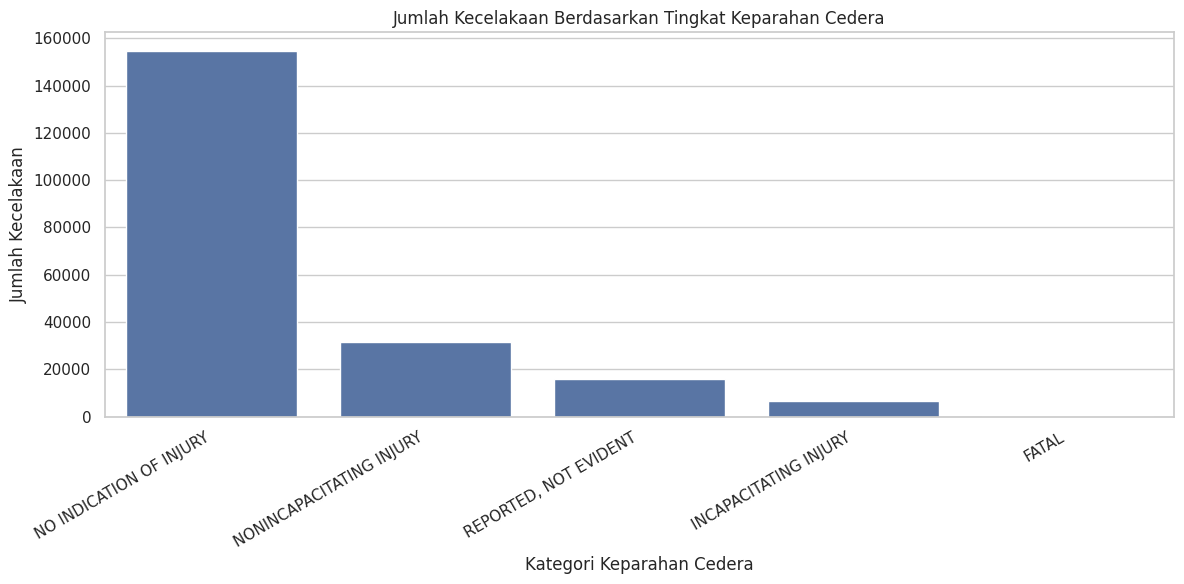

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# Mengurutkan data berdasarkan jumlah kecelakaan
injury_data = accidents_by_injury.sort_values(
    "total_accidents",
    ascending=False
)

# Membuat visualisasi
plt.figure(figsize=(12, 6))

sns.barplot(
    data=injury_data,
    x="most_severe_injury",
    y="total_accidents"
)

plt.title("Jumlah Kecelakaan Berdasarkan Tingkat Keparahan Cedera")
plt.xlabel("Kategori Keparahan Cedera")
plt.ylabel("Jumlah Kecelakaan")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.savefig("accidents_by_injury.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("accidents_by_injury.png")

3.4. Kecelakaan Berdasarkan Jenis Kecelakaan

Pie chart digunakan untuk memperlihatkan proporsi masing-masing jenis kecelakaan terhadap keseluruhan kejadian.

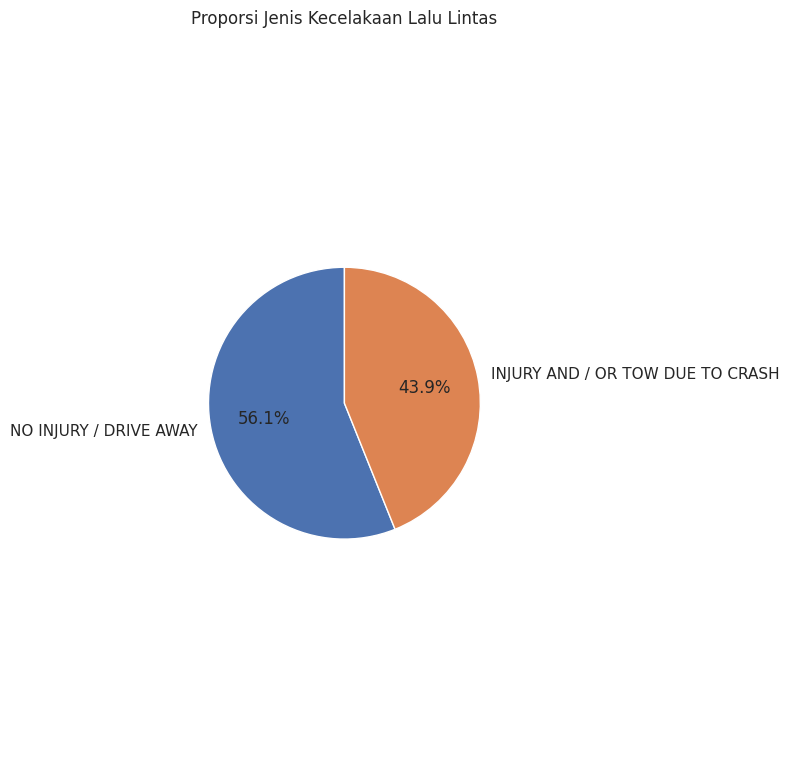

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# Mengambil data jenis kecelakaan
type_data = accidents_by_type.copy()

# Membuat visualisasi
plt.figure(figsize=(8, 8))

plt.pie(
    type_data["total_accidents"],
    labels=type_data["crash_type"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Proporsi Jenis Kecelakaan Lalu Lintas")
plt.axis("equal")

plt.tight_layout()

plt.savefig("accidents_by_type.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("accidents_by_type.png")

3.5. Kecelakaan Berdasarkan Kondisi Cuaca

Grafik horizontal dipilih karena nama kategori cuaca cukup panjang sehingga lebih mudah dibaca.

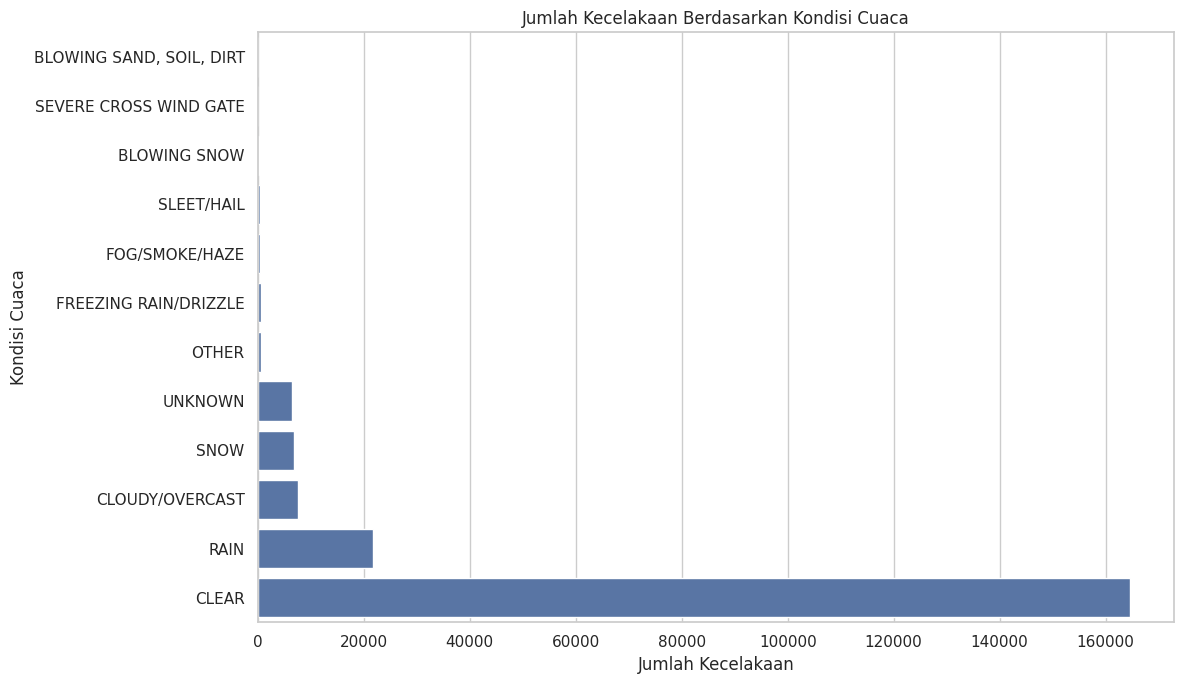

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
# Mengurutkan data berdasarkan jumlah kecelakaan
weather_data = accidents_by_weather.sort_values(
    "total_accidents",
    ascending=True
)

# Membuat visualisasi
plt.figure(figsize=(12, 7))

sns.barplot(
    data=weather_data,
    x="total_accidents",
    y="weather_condition"
)

plt.title("Jumlah Kecelakaan Berdasarkan Kondisi Cuaca")
plt.xlabel("Jumlah Kecelakaan")
plt.ylabel("Kondisi Cuaca")

plt.tight_layout()

# Menyimpan grafik
output_path = "/content/accidents_by_weather.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")

# Menampilkan grafik
plt.show()

# Mengunduh grafik ke komputer
files.download(output_path)

3.6. Kecelakaan Berdasarkan Kondisi Permukaan Jalan

Bar chart memudahkan perbandingan jumlah kecelakaan berdasarkan kategori kondisi permukaan jalan.

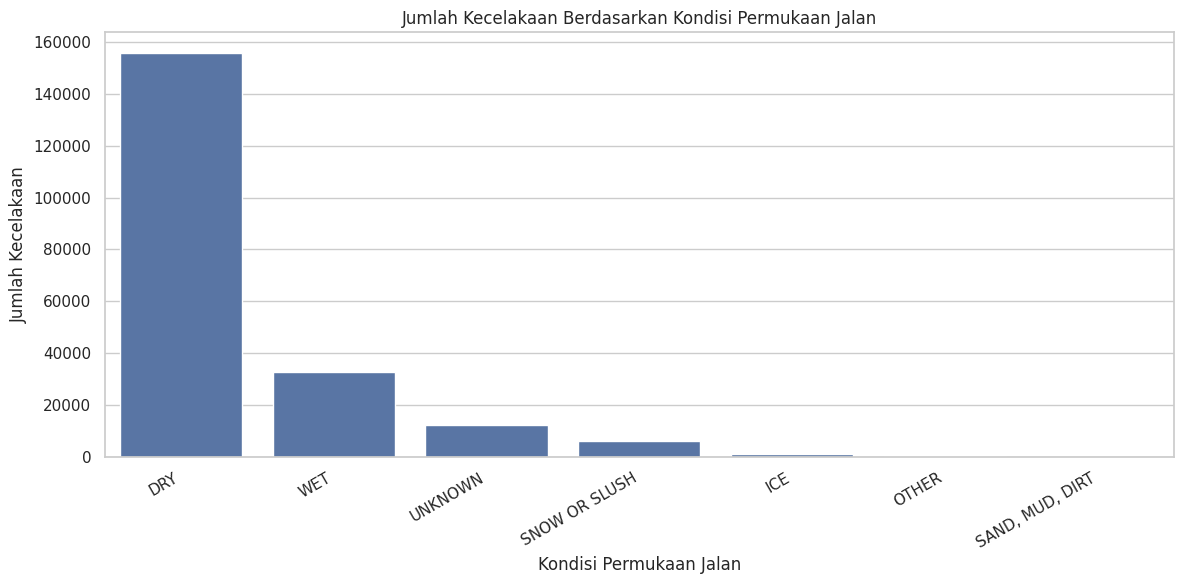

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
# Mengurutkan data berdasarkan jumlah kecelakaan
road_data = accidents_by_road_surface.sort_values(
    "total_accidents",
    ascending=False
)

# Membuat visualisasi
plt.figure(figsize=(12, 6))

sns.barplot(
    data=road_data,
    x="roadway_surface_cond",
    y="total_accidents"
)

plt.title("Jumlah Kecelakaan Berdasarkan Kondisi Permukaan Jalan")
plt.xlabel("Kondisi Permukaan Jalan")
plt.ylabel("Jumlah Kecelakaan")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.savefig("accidents_by_road_surface.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("accidents_by_road_surface.png")

3.7. Kecelakaan Berdasarkan Jam Kejadian

Line chart dipilih karena jam kejadian memiliki urutan waktu dari pukul 00.00 sampai 23.00 sehingga pola perubahan jumlah kecelakaan mudah diamati.

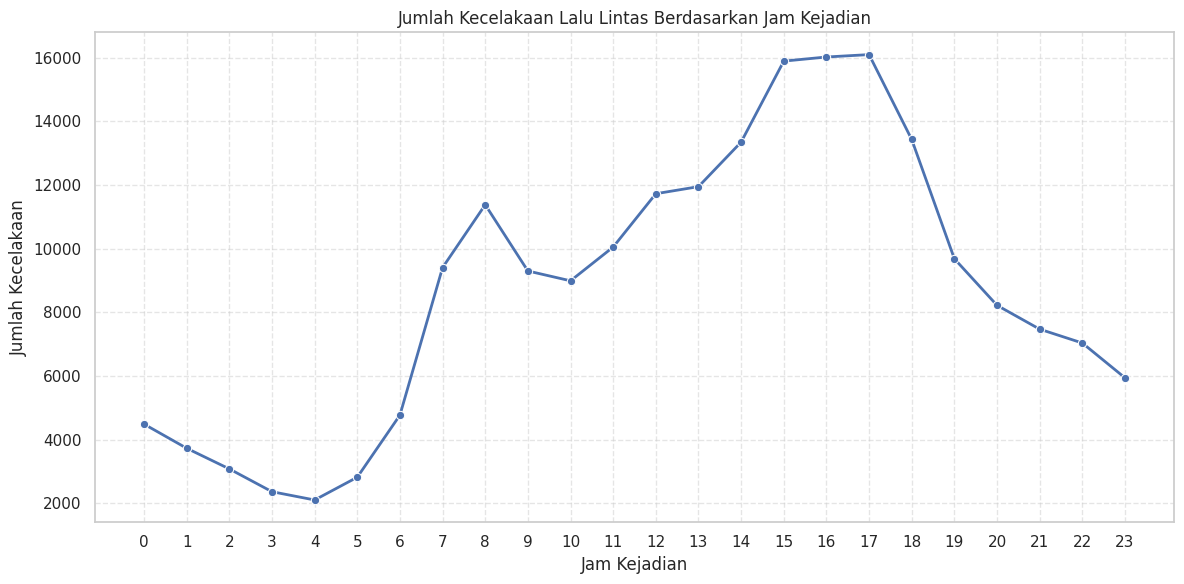

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# Mengurutkan data berdasarkan jam kejadian
hour_data = accidents_by_hour.sort_values("crash_hour")

# Membuat visualisasi
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hour_data,
    x="crash_hour",
    y="total_accidents",
    marker="o",
    linewidth=2
)

plt.title("Jumlah Kecelakaan Lalu Lintas Berdasarkan Jam Kejadian")
plt.xlabel("Jam Kejadian")
plt.ylabel("Jumlah Kecelakaan")
plt.xticks(range(24))
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig("accidents_by_hour.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("accidents_by_hour.png")

3.8. Kecelakaan Berdasarkan Hari Kejadian

Bar chart memudahkan perbandingan jumlah kecelakaan pada setiap hari dalam satu minggu.

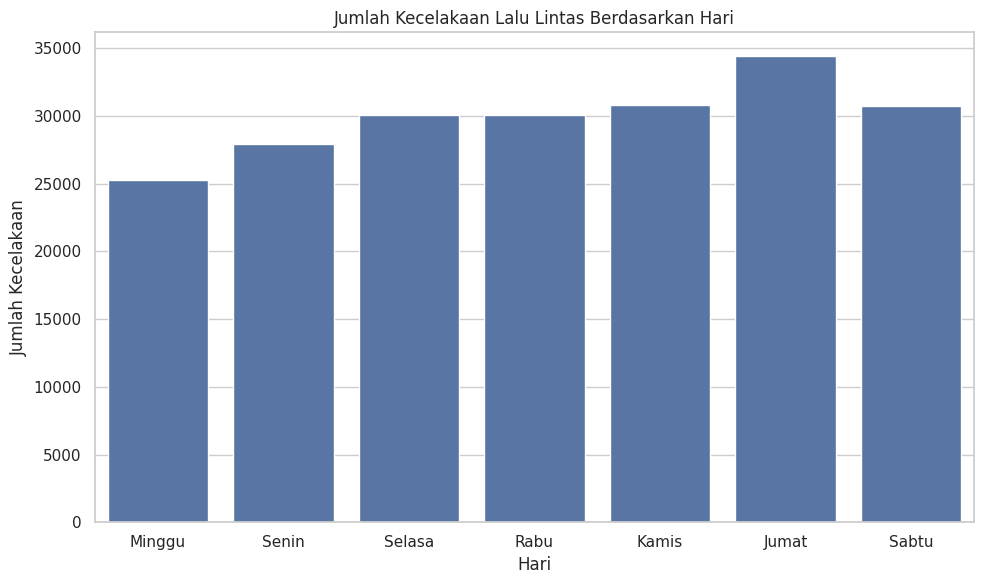

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# Mengurutkan data berdasarkan hari
day_data = accidents_by_day.sort_values("crash_day_of_week").copy()

# Mengubah angka hari menjadi nama hari
day_labels = {
    1: "Minggu",
    2: "Senin",
    3: "Selasa",
    4: "Rabu",
    5: "Kamis",
    6: "Jumat",
    7: "Sabtu"
}

day_data["day_name"] = day_data["crash_day_of_week"].map(day_labels)

# Membuat visualisasi
plt.figure(figsize=(10, 6))

sns.barplot(
    data=day_data,
    x="day_name",
    y="total_accidents"
)

plt.title("Jumlah Kecelakaan Lalu Lintas Berdasarkan Hari")
plt.xlabel("Hari")
plt.ylabel("Jumlah Kecelakaan")

plt.tight_layout()

plt.savefig("accidents_by_day.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("accidents_by_day.png")

3.9. Kecelakaan Berdasarkan Penyebab Utama

Grafik horizontal dipilih karena nama kategori penyebab kecelakaan cukup panjang. Kita menampilkan 10 kategori dengan jumlah kejadian terbanyak agar grafik tetap mudah dibaca.

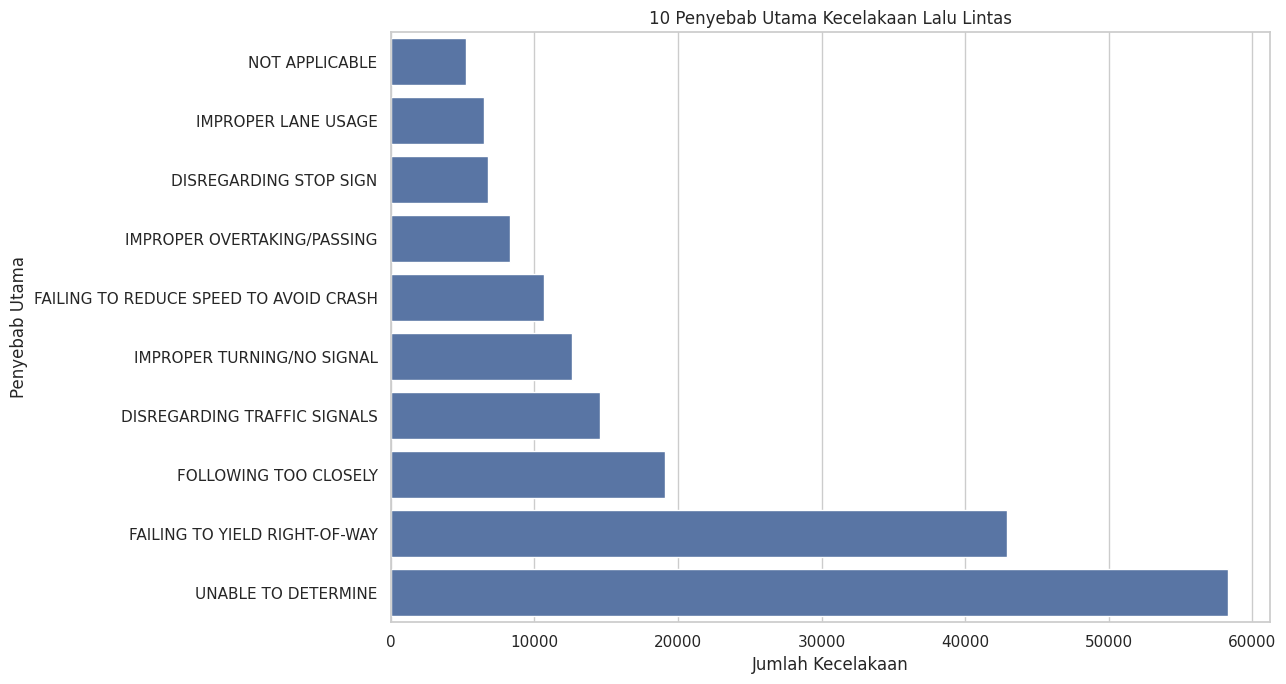

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
# Mengambil 10 kategori penyebab dengan jumlah kecelakaan tertinggi
cause_data = accidents_by_cause.nlargest(
    10,
    "total_accidents"
).sort_values("total_accidents", ascending=True)

# Membuat visualisasi
plt.figure(figsize=(13, 7))

sns.barplot(
    data=cause_data,
    x="total_accidents",
    y="prim_contributory_cause"
)

plt.title("10 Penyebab Utama Kecelakaan Lalu Lintas")
plt.xlabel("Jumlah Kecelakaan")
plt.ylabel("Penyebab Utama")

plt.tight_layout()

plt.savefig("accidents_by_cause.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("accidents_by_cause.png")

4. Interpretasi Hasil Visualisasi

Bagian ini membahas hasil visualisasi untuk mengidentifikasi pola dan distribusi kecelakaan lalu lintas berdasarkan sembilan atribut yang telah dianalisis.

4.1 Kecelakaan Berdasarkan Tahun



Berdasarkan hasil agregasi, jumlah kecelakaan tertinggi terjadi pada tahun 2019 sebanyak 27.947 kejadian. Sementara itu, tahun 2013 memiliki jumlah paling sedikit, yaitu 2 kejadian. Namun, data tahun 2013 dan 2025 merupakan data parsial sehingga tidak dapat dibandingkan secara langsung dengan tahun penuh.

4.2 Kecelakaan Berdasarkan Bulan

Jumlah kecelakaan tertinggi tercatat pada bulan Oktober sebanyak 20.088 kejadian, sedangkan jumlah terendah terjadi pada bulan Februari sebanyak 14.617 kejadian.

4.3 Tingkat Keparahan Cedera

Kategori NO INDICATION OF INJURY memiliki jumlah terbanyak, yaitu 154.767 kejadian. Sementara itu, kategori FATAL memiliki jumlah paling sedikit, yaitu 351 kejadian.

4.4 Jenis Kecelakaan

Jenis kecelakaan NO INJURY / DRIVE AWAY mendominasi dengan 117.356 kejadian, sedangkan INJURY AND / OR TOW DUE TO CRASH tercatat sebanyak 91.919 kejadian.

4.5 Kondisi Cuaca

Kondisi cuaca CLEAR memiliki jumlah kecelakaan tertinggi sebanyak 164.673 kejadian. Hal ini menunjukkan bahwa sebagian besar kecelakaan dalam dataset tercatat terjadi pada kondisi cuaca cerah.

4.6 Kondisi Permukaan Jalan

Kondisi permukaan jalan DRY mendominasi dengan 155.878 kejadian, diikuti kondisi WET sebanyak 32.906 kejadian.

4.7 Jam Kejadian

Jumlah kecelakaan tertinggi terjadi pada pukul 17.00 sebanyak 16.095 kejadian, sedangkan jumlah terendah terjadi pada pukul 04.00 sebanyak 2.104 kejadian.

4.8 Hari Kejadian

Hari Jumat memiliki jumlah kecelakaan tertinggi sebanyak 34.453 kejadian, sedangkan hari Minggu memiliki jumlah terendah sebanyak 25.245 kejadian.

4.9 Penyebab Utama Kecelakaan

Kategori UNABLE TO DETERMINE merupakan kategori dengan jumlah tertinggi sebanyak 58.310 kejadian, diikuti FAILING TO YIELD RIGHT-OF-WAY sebanyak 42.909 kejadian. Kategori UNABLE TO DETERMINE menunjukkan bahwa penyebab kecelakaan tidak dapat ditentukan berdasarkan pencatatan data.

# 5. Kesimpulan

Berdasarkan hasil visualisasi, data kecelakaan lalu lintas menunjukkan variasi jumlah kejadian berdasarkan waktu, tingkat keparahan cedera, jenis kecelakaan, kondisi cuaca, kondisi permukaan jalan, dan penyebab utama kecelakaan.

Visualisasi membantu mengidentifikasi pola distribusi kecelakaan, seperti jumlah kejadian tertinggi pada tahun 2019, bulan Oktober, pukul 17.00, dan hari Jumat. Seluruh hasil visualisasi ini memberikan gambaran deskriptif mengenai karakteristik kecelakaan lalu lintas dan menjadi bagian dari hasil analisis pada proyek Road Safety Data Pipeline.